# 01 · Demand Preparation & Exploration

**Project:** Demand Forecasting & Inventory Optimisation
**Company:** the UK online gift retailer from my customer segmentation project (UCI *Online Retail* dataset, Dec 2010 to Dec 2011).
**Business question:** how much of each top product should the retailer order every week to keep customers supplied **without tying up cash in excess stock**?

**This notebook** turns raw invoice lines into a clean **weekly demand table** for 5 top-selling products, ready for forecasting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.1f}".format)

raw = pd.read_csv("../data/online_retail.csv", dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": str})
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%Y %H:%M")
raw.shape

(541909, 8)

## 1. What counts as "demand"?

For stock planning, demand = **units customers ordered**. So we keep sales lines only:
- no cancellations (invoice starting with "C"); returns don't need stock to be shipped out
- positive quantity and price

In [2]:
sales = raw[~raw["InvoiceNo"].str.startswith("C") & (raw["Quantity"] > 0) & (raw["UnitPrice"] > 0)].copy()
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
print(f"{len(sales):,} sales lines")

530,104 sales lines


## 2. Choose the products

Forecasting works best for products that sell **regularly**. We pick the **5 highest-revenue products that sold on at least 280 of the ~305 trading days**.
This excludes, for example, the "Paper Craft, Little Birdie" item that appears to be a top seller only because of one 80,995-unit order that was cancelled 12 minutes later.

In [3]:
prod = sales[sales["StockCode"].str.match(r"^\d{5}")].groupby("StockCode").agg(
    Description=("Description", "first"),
    Revenue=("Revenue", "sum"),
    Units=("Quantity", "sum"),
    SellingDays=("InvoiceDate", lambda d: d.dt.date.nunique()),
    Customers=("CustomerID", "nunique"),
    TypicalPrice=("UnitPrice", "median"),
)
PRODUCTS = prod[prod["SellingDays"] >= 280].sort_values("Revenue", ascending=False).head(5)
SHORT = {"22423": "Cakestand", "85123A": "T-Light Holder", "47566": "Party Bunting",
         "85099B": "Jumbo Bag", "84879": "Bird Ornament"}
PRODUCTS["Short"] = PRODUCTS.index.map(SHORT)
print(f"These 5 products = £{PRODUCTS['Revenue'].sum():,.0f} revenue ({PRODUCTS['Revenue'].sum() / sales['Revenue'].sum():.1%} of all sales)")
PRODUCTS

These 5 products = £531,943 revenue (5.0% of all sales)


,Description,Revenue,Units,SellingDays,Customers,TypicalPrice,Short
StockCode,,,,,,,
22423,REGENCY CAKESTAND 3 TIER,"174,484.7",13879,301,881,12.8,Cakestand
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,518.8",37660,305,856,3.0,T-Light Holder
47566,PARTY BUNTING,"99,504.3",18295,294,708,5.0,Party Bunting
85099B,JUMBO BAG RED RETROSPOT,"94,340.1",48474,300,635,2.1,Jumbo Bag
84879,ASSORTED COLOUR BIRD ORNAMENT,"59,094.9",36461,300,678,1.7,Bird Ornament


In [4]:
lines = sales[sales["StockCode"].isin(PRODUCTS.index)].copy()
lines["Product"] = lines["StockCode"].map(SHORT)
ORDER = list(PRODUCTS["Short"])

## 3. Trading days and closures

The shop **never trades on Saturdays** and closes over Christmas and on UK bank holidays.
A week with 4 trading days will naturally sell less than a week with 6. That's a calendar effect, not lower demand, so we count trading days per week.

In [5]:
daily_activity = raw.set_index("InvoiceDate").resample("D").size()
trading_days = daily_activity[daily_activity > 0].index.normalize()
closed = daily_activity[(daily_activity == 0) & (daily_activity.index.dayofweek != 5)].index
print("Closed days (excluding Saturdays):")
print(", ".join(d.strftime("%a %d %b %Y") for d in closed))

Closed days (excluding Saturdays):
Fri 24 Dec 2010, Sun 26 Dec 2010, Mon 27 Dec 2010, Tue 28 Dec 2010, Wed 29 Dec 2010, Thu 30 Dec 2010, Fri 31 Dec 2010, Sun 02 Jan 2011, Mon 03 Jan 2011, Fri 22 Apr 2011, Sun 24 Apr 2011, Mon 25 Apr 2011, Fri 29 Apr 2011, Mon 02 May 2011, Mon 30 May 2011, Mon 29 Aug 2011


Besides Christmas–New Year, the closures are UK bank holidays: Good Friday & Easter Monday, **29 April 2011 (the royal wedding)**, the early-May, spring and August bank holidays.

## 4. Weekly aggregation

We plan in **weeks (Monday–Sunday)**:
- daily sales are noisy, and a retailer typically reorders weekly
- we keep only **complete weeks**: the first (from Wed 1 Dec 2010) and last (to Fri 9 Dec 2011) are partial

In [6]:
week_of = lambda ts: ts.dt.to_period("W-SUN").dt.start_time
lines["Week"] = week_of(lines["InvoiceDate"]).astype("datetime64[ns]")
td = pd.Series(1, index=trading_days).groupby(trading_days.to_period("W-SUN").start_time).sum().rename("TradingDays")
td.index = td.index.astype("datetime64[ns]")

all_weeks = pd.date_range(lines["Week"].min(), lines["Week"].max(), freq="W-MON")
complete_weeks = all_weeks[1:-1]
print(f"{len(complete_weeks)} complete weeks: {complete_weeks[0]:%d %b %Y} to {complete_weeks[-1] + pd.Timedelta(days=6):%d %b %Y}")

52 complete weeks: 06 Dec 2010 to 04 Dec 2011


## 5. Big wholesale orders

Many customers are **wholesalers**. Most order lines are small, but a few are huge:

In [7]:
line_stats = lines.groupby("Product")["Quantity"].describe(percentiles=[.5, .9, .99])[["count", "50%", "90%", "99%", "max"]]
line_stats.loc[ORDER]

,count,50%,90%,99%,max
Product,,,,,
Cakestand,"2,017.0",2.0,16.0,64.0,272.0
T-Light Holder,"2,265.0",6.0,32.0,153.6,"1,930.0"
Party Bunting,"1,706.0",4.0,24.0,100.0,200.0
Jumbo Bag,"2,112.0",10.0,60.0,200.0,"1,200.0"
Bird Ornament,"1,489.0",12.0,40.0,160.0,"2,880.0"


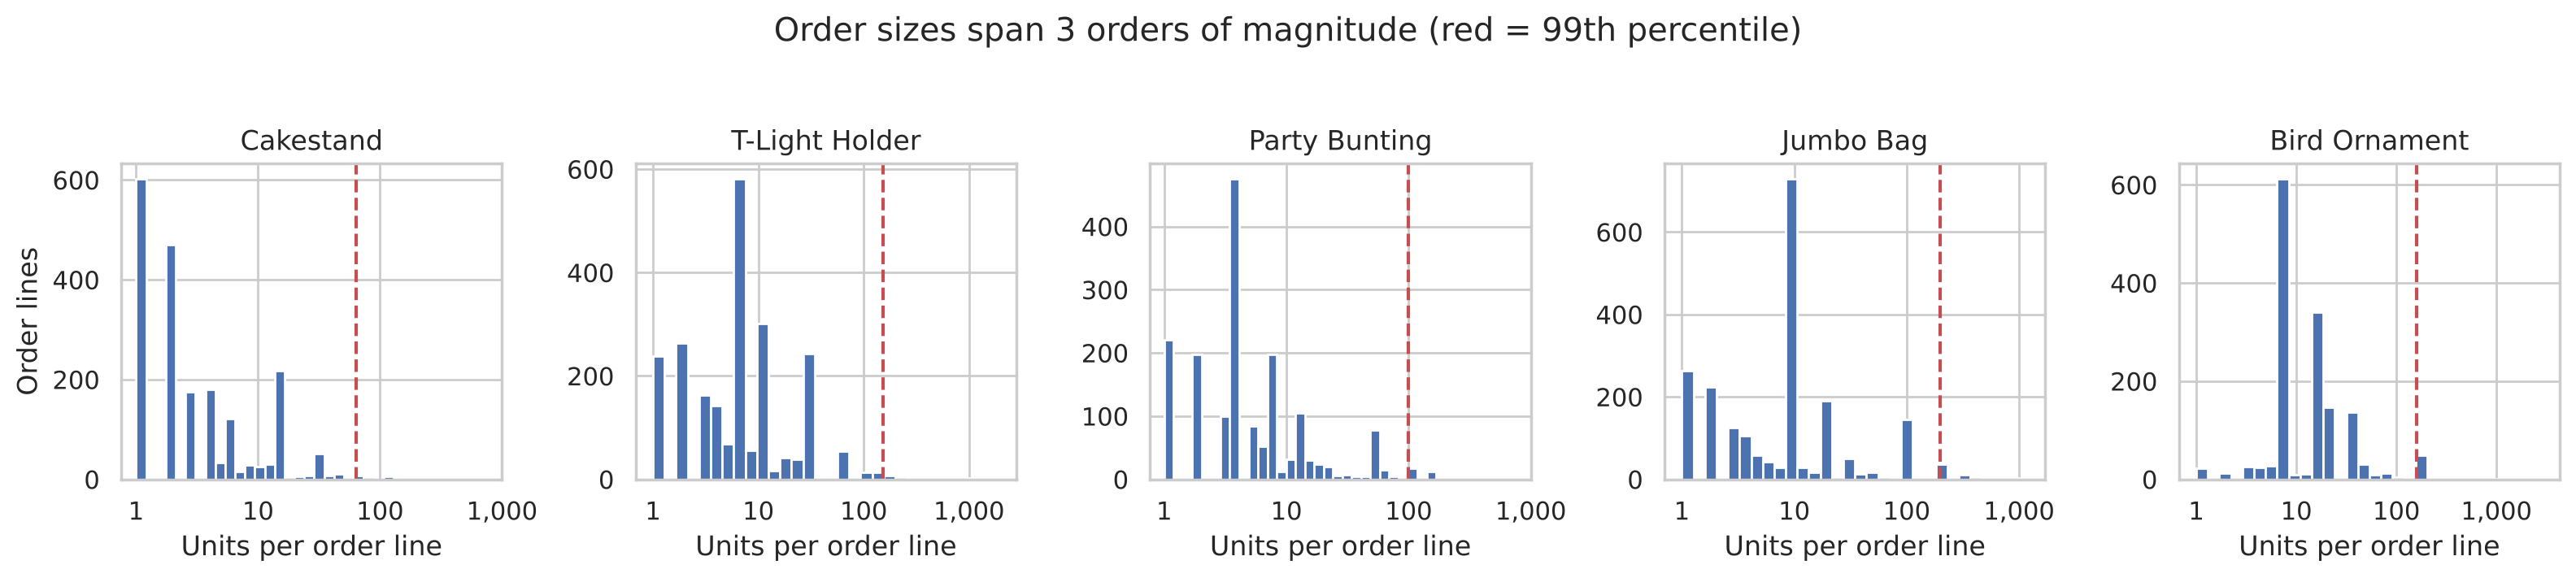

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4), sharey=False)
for ax, p in zip(axes, ORDER):
    q = lines.loc[lines["Product"] == p, "Quantity"]
    ax.hist(np.log10(q), bins=30, color="#4C72B0")
    ax.axvline(np.log10(q.quantile(0.99)), color="#C44E52", ls="--", lw=1.5)
    ax.set_title(p); ax.set_xlabel("Units per order line")
    ax.set_xticks([0, 1, 2, 3]); ax.set_xticklabels(["1", "10", "100", "1,000"])
axes[0].set_ylabel("Order lines")
fig.suptitle("Order sizes span 3 orders of magnitude (red = 99th percentile)", y=1.04)
plt.tight_layout()
plt.savefig("../reports/figures/01_order_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

### Decision: split demand into *regular* and *bulk*

An order line larger than the product's **99th percentile line size** is treated as a **bulk order**.

- **Regular demand** = many small orders. It behaves like a smooth stream and **can be forecast**.
- **Bulk orders** = rare, huge, one customer at a time. **No weekly model can predict them** from history.
  Keeping enough stock "just in case" for them would mean permanently holding several weeks of extra inventory.

**Business recommendation:** handle bulk orders like a B2B process: wholesalers order a few weeks **in advance** (or accept a longer delivery time), so the
retailer buys stock for them specifically. The forecast and the optimisation model then plan **regular demand** only.

To avoid peeking at the future, the thresholds are computed on the **first 40 weeks** only (the later weeks are the forecast test period).

In [9]:
TRAIN_END = complete_weeks[39]          # weeks 1–40 = training, weeks 41–52 = test (used in notebook 02)
train_lines = lines[lines["Week"] <= TRAIN_END]
BULK_THRESHOLD = train_lines.groupby("Product")["Quantity"].quantile(0.99).round()
lines["IsBulk"] = lines["Quantity"] > lines["Product"].map(BULK_THRESHOLD)

bulk_summary = lines.groupby("Product").apply(lambda g: pd.Series({
    "Bulk threshold (units/line)": BULK_THRESHOLD[g.name],
    "Bulk lines": g["IsBulk"].sum(),
    "% of lines": g["IsBulk"].mean() * 100,
    "% of units": g.loc[g["IsBulk"], "Quantity"].sum() / g["Quantity"].sum() * 100,
}), include_groups=False).loc[ORDER]
bulk_summary

,Bulk threshold (units/line),Bulk lines,% of lines,% of units
Product,,,,
Cakestand,67.0,20.0,1.0,17.3
T-Light Holder,128.0,25.0,1.1,31.3
Party Bunting,100.0,15.0,0.9,12.2
Jumbo Bag,200.0,21.0,1.0,18.5
Bird Ornament,160.0,4.0,0.3,14.7


Roughly **1% of order lines carry 12–31% of all units**. That's exactly the kind of concentration that makes a single forecast unreliable.

## 6. Build the weekly demand table

In [10]:
weekly = (lines.groupby(["Week", "Product"])
          .apply(lambda g: pd.Series({"Regular": g.loc[~g["IsBulk"], "Quantity"].sum(),
                                      "Bulk": g.loc[g["IsBulk"], "Quantity"].sum()}), include_groups=False)
          .reset_index())
grid = pd.MultiIndex.from_product([complete_weeks, ORDER], names=["Week", "Product"]).to_frame(index=False)
weekly = grid.merge(weekly, on=["Week", "Product"], how="left").fillna({"Regular": 0, "Bulk": 0})
weekly = weekly.merge(td.rename_axis("Week").reset_index(), on="Week", how="left").fillna({"TradingDays": 0})
weekly["Total"] = weekly["Regular"] + weekly["Bulk"]
weekly["Closed"] = weekly["TradingDays"] == 0
weekly["Split"] = np.where(weekly["Week"] <= TRAIN_END, "train", "test")

print(weekly["TradingDays"].value_counts().sort_index().rename("weeks (x5 products)"))
weekly[weekly["Product"] == "Cakestand"].head(6)

TradingDays
0.0      5
4.0     15
5.0     20
6.0    220
Name: weeks (x5 products), dtype: int64


,Week,Product,Regular,Bulk,TradingDays,Total,Closed,Split
0,2010-12-06,Cakestand,499.0,352.0,6.0,851.0,False,train
5,2010-12-13,Cakestand,362.0,80.0,6.0,442.0,False,train
10,2010-12-20,Cakestand,99.0,79.0,4.0,178.0,False,train
15,2010-12-27,Cakestand,0.0,0.0,0.0,0.0,True,train
20,2011-01-03,Cakestand,251.0,0.0,5.0,251.0,False,train
25,2011-01-10,Cakestand,247.0,160.0,6.0,407.0,False,train


- Normal weeks have **6 trading days** (Sunday–Friday; the shop never trades on Saturdays). Bank-holiday weeks have **4 or 5**.
- One week has **0 trading days** (27 Dec – 2 Jan): the shop was closed. That's **not zero demand**; it's missing data.
  It's excluded from model training, and in planning, no order is needed for a closed week.

## 7. Weekly demand over the year

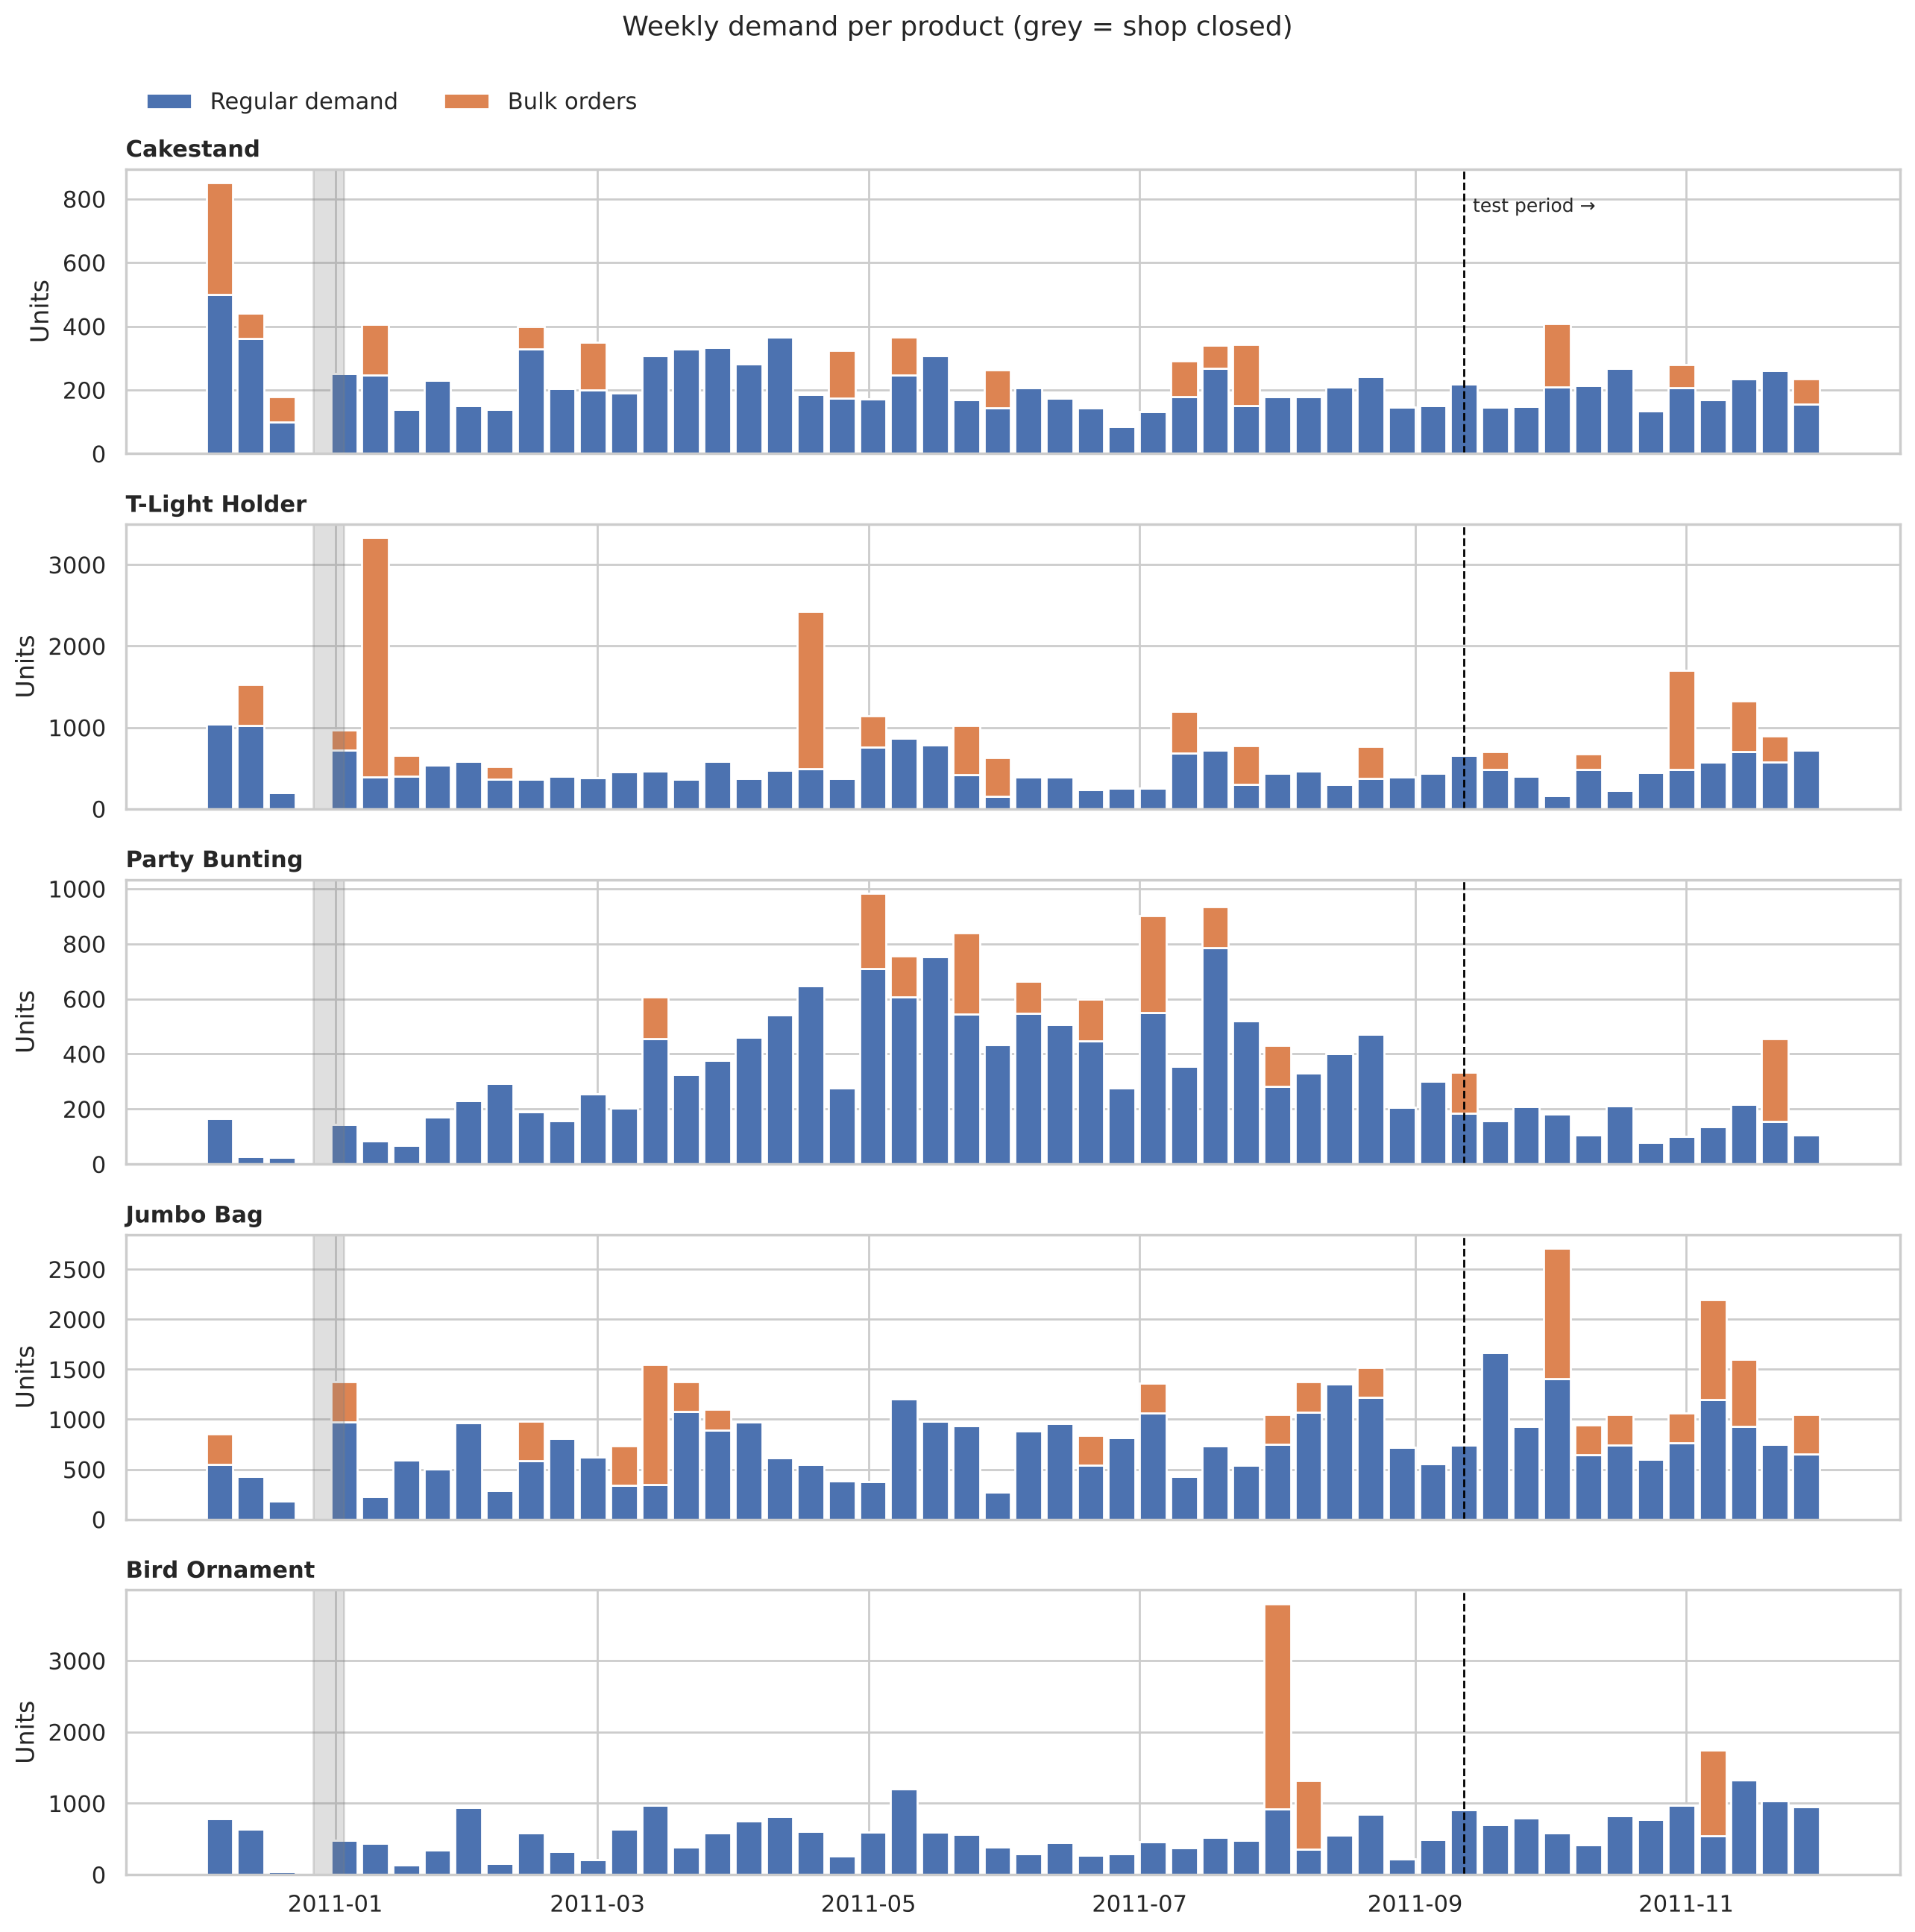

In [11]:
fig, axes = plt.subplots(5, 1, figsize=(13, 13), sharex=True)
for ax, p in zip(axes, ORDER):
    w = weekly[weekly["Product"] == p].set_index("Week")
    ax.bar(w.index, w["Regular"], width=6, color="#4C72B0", label="Regular demand")
    ax.bar(w.index, w["Bulk"], width=6, bottom=w["Regular"], color="#DD8452", label="Bulk orders")
    for wk in w.index[w["Closed"]]:
        ax.axvspan(wk, wk + pd.Timedelta(days=7), color="grey", alpha=0.25)
    ax.axvline(TRAIN_END + pd.Timedelta(days=7), color="black", ls="--", lw=1)
    ax.set_ylabel("Units"); ax.set_title(p, loc="left", fontsize=11, fontweight="bold")
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.12), ncol=2, frameon=False)
axes[0].text(TRAIN_END + pd.Timedelta(days=9), axes[0].get_ylim()[1] * 0.85, "test period →", fontsize=9)
fig.suptitle("Weekly demand per product (grey = shop closed)", y=0.995, fontsize=13)
plt.tight_layout()
plt.savefig("../reports/figures/01_weekly_demand.png", dpi=150)
plt.show()

**What we see:**
- **Bulk orders** (orange) explain most of the extreme spikes, especially for the T-Light Holder, Jumbo Bag and Bird Ornament.
- **Regular demand** (blue) is much smoother, but still varies a lot week to week. That variability is what **safety stock** must cover.
- **Party Bunting is seasonal** (spring/summer garden parties) and fades in autumn; the **Bird Ornament and T-Light Holder** rise towards Christmas, while the **Jumbo Bag** peaks in late summer (see the seasonality table below).
- Our **test period (last 12 weeks, Sep–Dec)** is the busy pre-Christmas season. That's a tough but realistic test for any forecast.

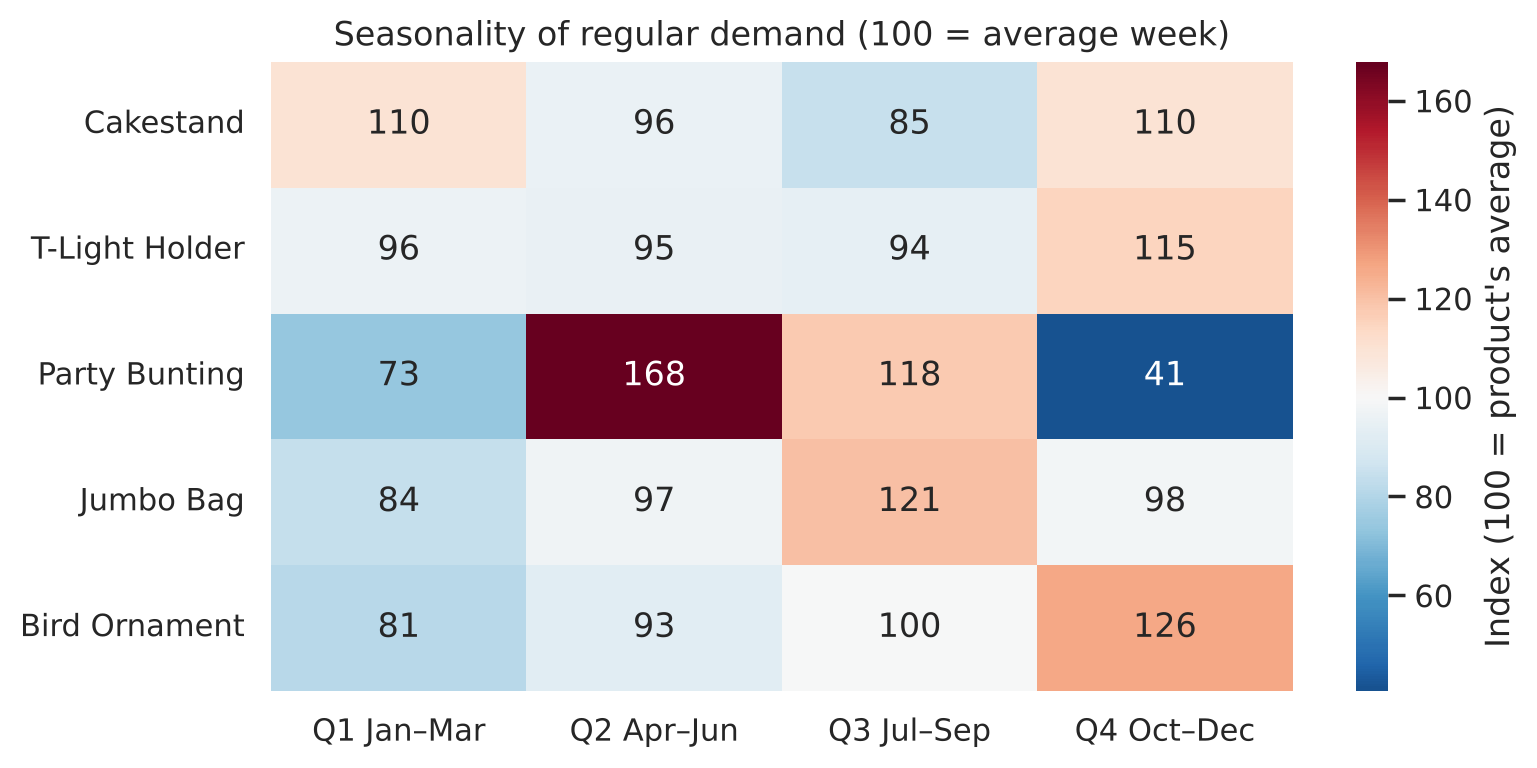

In [12]:
weekly["Quarter"] = weekly["Week"].dt.quarter.map({1: "Q1 Jan–Mar", 2: "Q2 Apr–Jun", 3: "Q3 Jul–Sep", 4: "Q4 Oct–Dec"})
open_weeks = weekly[~weekly["Closed"]]
seasonal = open_weeks.groupby(["Product", "Quarter"])["Regular"].mean().unstack().loc[ORDER]
idx = seasonal.div(seasonal.mean(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(idx, annot=True, fmt=".0f", cmap="RdBu_r", center=100, ax=ax, cbar_kws={"label": "Index (100 = product's average)"})
ax.set_title("Seasonality of regular demand (100 = average week)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../reports/figures/01_seasonality.png", dpi=150)
plt.show()

> ⚠️ **One year of data = one observation of each season.** We can *see* seasonality, but a model can't reliably *learn* it
> from a single year. The forecasting models in notebook 02 will therefore rely on **recent weeks** rather than last year's pattern.

## 8. How variable is regular demand?

In [13]:
cv = open_weeks.groupby("Product").apply(lambda g: pd.Series({
    "Mean / week": g["Regular"].mean(),
    "Std / week": g["Regular"].std(),
    "Coefficient of variation": g["Regular"].std() / g["Regular"].mean(),
    "Total CV (incl. bulk)": g["Total"].std() / g["Total"].mean(),
}), include_groups=False).loc[ORDER]
cv

,Mean / week,Std / week,Coefficient of variation,Total CV (incl. bulk)
Product,,,,
Cakestand,213.1,78.7,0.4,0.5
T-Light Holder,481.8,199.7,0.4,0.8
Party Bunting,313.2,196.9,0.6,0.7
Jumbo Bag,752.0,323.0,0.4,0.5
Bird Ornament,585.0,283.0,0.5,0.8


Removing bulk orders makes demand clearly more predictable (a lower coefficient of variation for every product). Regular demand still varies by about **40–60%** per week, so
uncertainty must be built into the ordering decision; a single "best guess" isn't enough.

## 9. Save

In [14]:
PRODUCTS[["Short", "Description", "TypicalPrice", "Revenue", "Units"]].rename(columns={"Short": "Product"}).to_csv("../data/products.csv")
weekly.drop(columns=["Quarter"]).to_csv("../data/weekly_demand.csv", index=False)
weekly.shape

(260, 9)

## Key takeaways

1. **5 products, £532k revenue** (5% of all sales), each selling on 290+ of ~305 trading days.
2. **Calendar effects matter:** Saturdays, Christmas and 6 bank holidays (incl. the royal wedding) reduce trading days. We track them so a short week isn't mistaken for weak demand.
3. **About 1% of order lines (bulk wholesale orders) carry 12–31% of units.** They're unforecastable from history, so the recommendation is to take them as **advance orders**, and we plan **regular demand** only.
4. Products have **different seasonal patterns**, but one year of history can't teach a model seasonality reliably.
5. Regular demand still varies **40–60% week to week**, so the ordering decision must include a **safety buffer**.

**Next → `02_forecasting.ipynb`:** forecast weekly regular demand and, just as important, measure **how wrong the forecasts are**.